In [ ]:
import re
import pandas as pd
import numpy as np
from scipy import stats

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
print("Colab:", IN_COLAB)

Colab: True


In [ ]:
if IN_COLAB:
    up = files.upload()
    nama_file = list(up.keys())[0]
else:
    nama_file = "/mnt/user-data/uploads/Blank_Quiz__Responses_.xlsx"
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses 3 TIC).xlsx to Blank Quiz (Responses 3 TIC).xlsx
File terbaca: Blank Quiz (Responses 3 TIC).xlsx


In [ ]:
df_awal = pd.read_excel(nama_file)
print("Total responden semua kelas:", len(df_awal))
print(df_awal["Kelas"].value_counts(), "\n")

# filter dulu, baru kolom Kelas dibuang
df = df_awal[df_awal["Kelas"].str.strip() == "3 TI C"].copy()

# Timestamp = waktu pengisian; Score = skor bawaan Google Forms (semuanya 0, tidak bermakna)
df = df.drop(columns=["Timestamp", "Kelas"]).reset_index(drop=True)
print("Responden 3 TI C :", len(df))
print("Jumlah kolom     :", df.shape[1])
print("Data kosong      :", int(df.isna().sum().sum()))

Total responden semua kelas: 40
Kelas
3 TI C    40
Name: count, dtype: int64 

Responden 3 TI C : 40
Jumlah kolom     : 33
Data kosong      : 0


In [ ]:
# Laki-laki = 1, Perempuan = 2
df["Jenis Kelamin"] = df["Jenis Kelamin"].str.strip().map({"Laki-laki": 1, "Perempuan": 2})
print("Jenis kelamin gagal dikonversi:", int(df["Jenis Kelamin"].isna().sum()))

KATA_ANGKA = {"nol":0,"satu":1,"dua":2,"tiga":3,"empat":4,"lima":5,
              "enam":6,"tujuh":7,"delapan":8,"sembilan":9,"sepuluh":10}

def normalisasi_jumlah(v):
    """Ubah isian campuran (angka, 'tiga', 'belum ada', 'Satu (Gemini)') menjadi angka."""
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    s = str(v).strip().lower()
    if re.search(r"\b(belum|tidak|nggak|gak|ga)\b", s):
        return 0.0
    angka = [float(a) for a in re.findall(r"\d+", s)]
    if not angka:
        angka = [KATA_ANGKA[k] for k in re.findall(r"[a-z]+", s) if k in KATA_ANGKA]
    # jika rentang (mis. '3 atau 4') dipakai rata-ratanya
    return float(np.mean(angka)) if angka else np.nan

kol_platform = [c for c in df.columns if c.startswith("Jumlah Platform AI")]
for k in kol_platform:
    asli = df[k].copy()
    df[k] = asli.map(normalisasi_jumlah).astype(int)
    diubah = pd.DataFrame({"sebelum": asli, "sesudah": df[k]})
    diubah = diubah[diubah["sebelum"].map(lambda v: isinstance(v, str))]
    print("\n" + k)
    print(diubah.to_string() if len(diubah) else "(tidak ada isian string)")

Jenis kelamin gagal dikonversi: 0

Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek (isi dengan num/angka)
(tidak ada isian string)

Jumlah Platform AI yang berlangganan premium atau tidak free (isi dengan num/angka)
(tidak ada isian string)


In [ ]:
# durasi gadget tidak diuji
kol_durasi = [c for c in df.columns if c.startswith("Durasi (jam)")]
df = df.drop(columns=kol_durasi)

# kolom awal = jenis kelamin + 2 kolom jumlah platform AI (bukan skala Likert)
JUMLAH_KOLOM_DEMOGRAFI = 3
data_awal = df.iloc[:, :JUMLAH_KOLOM_DEMOGRAFI]
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Kolom awal (tidak diuji):")
for c in data_awal.columns: print(" -", c)
print("\nJumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Kolom awal (tidak diuji):
 - Jenis Kelamin
 - Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek (isi dengan num/angka)
 - Jumlah Platform AI yang berlangganan premium atau tidak free (isi dengan num/angka)

Jumlah responden : 40
Jumlah butir     : 29
Data kosong      : 0


In [ ]:
skala = {
    "Sangat Tidak Setuju (STJ)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip()).replace(skala).apply(pd.to_numeric, errors="coerce")
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_422/468731968.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.apply(lambda s: s.astype(str).str.strip()).replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,4,4,4,4,4,5,4,4,...,2,5,4,5,4,5,5,4,4,5
1,4,4,4,4,4,4,4,5,4,4,...,4,2,4,4,4,5,4,5,5,5
2,5,5,4,4,4,4,4,4,4,4,...,2,4,5,4,2,5,5,5,4,5
3,5,4,5,2,4,5,5,4,4,2,...,2,4,4,4,4,5,4,4,4,4
4,5,5,4,4,5,5,5,4,2,4,...,2,2,2,2,4,5,5,4,5,5


In [ ]:
dimensi = {}
for kolom in butir.columns:
    nama = kolom.split("[")[0].strip()
    dimensi.setdefault(nama, []).append(kolom)

# rapikan nama dimensi yang salah ketik / berakhiran titik
RAPI = {"Rsspon emosional": "Respon emosional", "Prokrastinasi akademik.": "Prokrastinasi akademik"}
dimensi = {RAPI.get(k, k): v for k, v in dimensi.items()}

kelompok = {
    "Penggunaan AI":    {k: v for k, v in dimensi.items() if k.startswith("Penggunaan AI")},
    "Aspek Psikologis": {k: v for k, v in dimensi.items() if not k.startswith("Penggunaan AI")},
}
for g, dims in kelompok.items():
    print(f"[{g}]")
    for nama, daftar in dims.items():
        print(f"   {nama}: {len(daftar)} butir")

[Penggunaan AI]
   Penggunaan AI pada tugas atau projek kuliah: 7 butir
[Aspek Psikologis]
   Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
   Kebiasaan penggunaan teknologi digital: 6 butir
   Prokrastinasi akademik: 4 butir
   Respon emosional: 5 butir


In [ ]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

def keputusan(valid, a_hapus, a_dim):
    if pd.isna(a_hapus):
        return "Pertahankan" if valid else "Tinjau ulang (dimensi ≤ 2 butir)"
    lebih_tinggi = a_hapus > a_dim
    if valid and not lebih_tinggi: return "Pertahankan"
    if not valid and lebih_tinggi: return "Buang atau revisi"
    if valid and lebih_tinggi:     return "Tinjau isi butir"
    return "Tinjau ulang sebelum dibuang"

def uji(dims):
    validitas, reliabilitas = [], []
    for nama, daftar in dims.items():
        x = num[daftar]
        total = x.sum(axis=1)
        a_dim = cronbach_alpha(x)
        reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                             "Cronbach's alpha": round(a_dim, 3), "Kategori": kategori(a_dim)})
        for i, kolom in enumerate(daftar, 1):
            r, p = stats.pearsonr(x[kolom], total)
            r_kor, _ = stats.pearsonr(x[kolom], total - x[kolom])
            a_hapus = cronbach_alpha(x.drop(columns=kolom)) if len(daftar) > 2 else np.nan
            valid = r > r_tabel
            validitas.append({
                "Dimensi": nama, "Butir": f"B{i}",
                "r hitung": round(r, 3), "r tabel": round(r_tabel, 3),
                "Corrected r": round(r_kor, 3), "p-value": round(p, 4),
                "Keterangan": "Valid" if valid else "Tidak valid",
                "Alpha jika dihapus": round(a_hapus, 3) if pd.notna(a_hapus) else np.nan,
                "Keputusan": keputusan(valid, a_hapus, a_dim),
            })
    return pd.DataFrame(validitas), pd.DataFrame(reliabilitas)
print("Fungsi siap.")

n = 40 | r tabel (α=0,05; df=38) = 0.312
Fungsi siap.


In [ ]:
val_ai, rel_ai = uji(kelompok["Penggunaan AI"])
display(val_ai)
display(rel_ai)

,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,Alpha jika dihapus,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.312,0.222,0.0071,Valid,0.531,Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.312,0.224,0.0129,Valid,0.533,Pertahankan
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,0.312,0.418,0.0000,Valid,0.456,Pertahankan
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.312,0.205,0.0009,Valid,0.547,Pertahankan
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,0.312,0.597,0.0000,Valid,0.341,Pertahankan
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,0.312,0.424,0.0000,Valid,0.453,Pertahankan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,0.1510,Tidak valid,0.639,Buang atau revisi


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.55,Tidak reliabel


In [ ]:
val_psi, rel_psi = uji(kelompok["Aspek Psikologis"])
display(val_psi)
display(rel_psi)

,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value,Keterangan,Alpha jika dihapus,Keputusan
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.578,0.312,0.437,0.0001,Valid,0.637,Pertahankan
1,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.708,0.312,0.541,0.0000,Valid,0.597,Pertahankan
2,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.804,0.312,0.651,0.0000,Valid,0.550,Pertahankan
3,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B4,0.675,0.312,0.481,0.0000,Valid,0.614,Pertahankan
4,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B5,0.797,0.312,0.636,0.0000,Valid,0.555,Pertahankan
5,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B6,0.389,0.312,0.208,0.0132,Valid,0.684,Tinjau isi butir
6,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.312,-0.272,0.5625,Tidak valid,0.769,Buang atau revisi
7,Kebiasaan penggunaan teknologi digital,B1,0.551,0.312,0.392,0.0002,Valid,0.812,Tinjau isi butir
8,Kebiasaan penggunaan teknologi digital,B2,0.567,0.312,0.434,0.0001,Valid,0.805,Pertahankan
9,Kebiasaan penggunaan teknologi digital,B3,0.819,0.312,0.706,0.0000,Valid,0.744,Pertahankan


,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,0.678,Tidak reliabel
1,Kebiasaan penggunaan teknologi digital,6,0.808,Baik
2,Prokrastinasi akademik,4,0.865,Baik
3,Respon emosional,5,0.555,Tidak reliabel


In [ ]:
ringkas = []
for g, v, r in [("Penggunaan AI", val_ai, rel_ai), ("Aspek Psikologis", val_psi, rel_psi)]:
    for _, d in r.iterrows():
        sub = v[v["Dimensi"] == d["Dimensi"]]
        ringkas.append({
            "Kelompok": g, "Dimensi": d["Dimensi"], "Butir": d["Jumlah butir"],
            "Valid": int((sub["Keterangan"] == "Valid").sum()),
            "Tidak valid": int((sub["Keterangan"] == "Tidak valid").sum()),
            "Valid jika corrected r ≥ 0,30": int((sub["Corrected r"] >= 0.30).sum()),
            "Alpha": d["Cronbach's alpha"], "Kategori alpha": d["Kategori"],
        })
tabel_ringkas = pd.DataFrame(ringkas)
tabel_ringkas

,Kelompok,Dimensi,Butir,Valid,Tidak valid,"Valid jika corrected r ≥ 0,30",Alpha,Kategori alpha
0,Penggunaan AI,Penggunaan AI pada tugas atau projek kuliah,7,6,1,3,0.550,Tidak reliabel
1,Aspek Psikologis,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,7,6,1,5,0.678,Tidak reliabel
2,Aspek Psikologis,Kebiasaan penggunaan teknologi digital,6,6,0,6,0.808,Baik
3,Aspek Psikologis,Prokrastinasi akademik,4,4,0,4,0.865,Baik
4,Aspek Psikologis,Respon emosional,5,5,0,3,0.555,Tidak reliabel


In [ ]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

nama_out = "hasil_uji_validitas_reliabilitas_3TIC.xlsx"
data_bersih = pd.concat([data_awal.reset_index(drop=True), num.reset_index(drop=True)], axis=1)

with pd.ExcelWriter(nama_out, engine="openpyxl") as w:
    tabel_ringkas.to_excel(w, sheet_name="Ringkasan", index=False)
    val_ai.to_excel(w, sheet_name="Validitas_AI", index=False)
    rel_ai.to_excel(w, sheet_name="Reliabilitas_AI", index=False)
    val_psi.to_excel(w, sheet_name="Validitas_Psikologis", index=False)
    rel_psi.to_excel(w, sheet_name="Reliabilitas_Psikologis", index=False)
    data_bersih.to_excel(w, sheet_name="Data_Bersih", index=False)
    for ws in w.book.worksheets:
        for cell in ws[1]:
            cell.font = Font(name="Arial", bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="305496")
            cell.alignment = Alignment(wrap_text=True, vertical="center")
        for row in ws.iter_rows(min_row=2):
            for cell in row: cell.font = Font(name="Arial")
        for i, col in enumerate(ws.columns, 1):
            if ws.title == "Data_Bersih":
                ws.column_dimensions[get_column_letter(i)].width = 14
            else:
                m = max(len(str(c.value)) if c.value is not None else 0 for c in col)
                ws.column_dimensions[get_column_letter(i)].width = min(max(12, m + 2), 40)
        ws.freeze_panes = "A2"

print("Tersimpan:", nama_out)
if IN_COLAB:
    files.download(nama_out)

Tersimpan: hasil_uji_validitas_reliabilitas_3TIC.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Latihan 1 — Interpretasi Butir Tidak Valid

Menampilkan butir yang tidak valid berdasarkan perbandingan **r hitung > r tabel**. Dugaan penyebab ditulis sebagai kemungkinan berdasarkan isi pernyataan, bukan sebagai kesimpulan pasti.

,Dimensi,Butir,r hitung,r tabel,Corrected r,p-value
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,0.312,-0.061,0.1510
13,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B7,-0.094,0.312,-0.272,0.5625


Jumlah butir tidak valid: 2


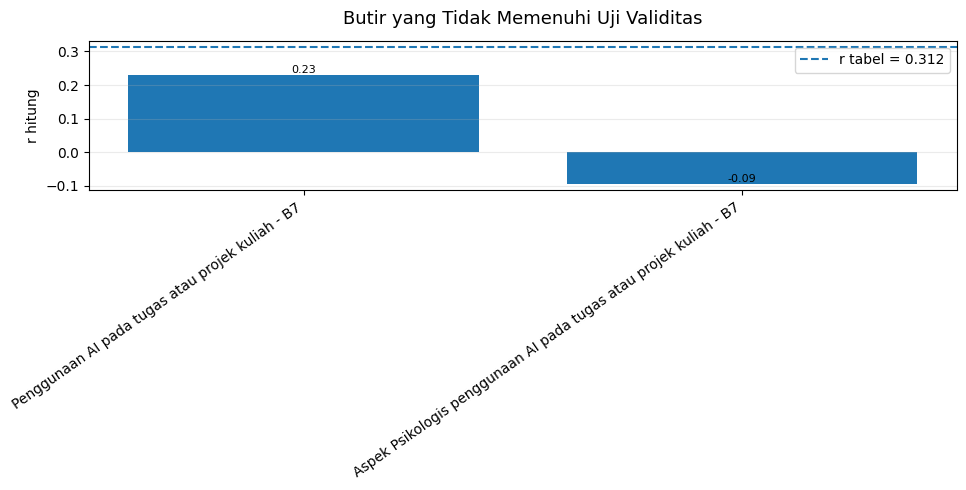

In [ ]:
# Menggabungkan hasil validitas dari seluruh dimensi
hasil_semua_validitas = pd.concat([val_ai, val_psi], ignore_index=True)

butir_tidak_valid = hasil_semua_validitas[
    hasil_semua_validitas["Keterangan"] == "Tidak valid"
].copy()

display(butir_tidak_valid[[
    "Dimensi", "Butir", "r hitung", "r tabel", "Corrected r", "p-value"
]])

print("Jumlah butir tidak valid:", len(butir_tidak_valid))

# Visualisasi butir yang tidak valid
import matplotlib.pyplot as plt

if len(butir_tidak_valid) > 0:
    plt.figure(figsize=(10, 5))
    label_butir = butir_tidak_valid["Dimensi"].astype(str) + " - " + butir_tidak_valid["Butir"].astype(str)
    bars = plt.bar(label_butir, butir_tidak_valid["r hitung"])
    plt.axhline(float(butir_tidak_valid["r tabel"].iloc[0]), linestyle="--",
                label=f"r tabel = {butir_tidak_valid['r tabel'].iloc[0]:.3f}")
    plt.title("Butir yang Tidak Memenuhi Uji Validitas", fontsize=13, pad=12)
    plt.ylabel("r hitung")
    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    for bar, nilai in zip(bars, butir_tidak_valid["r hitung"]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f"{nilai:.2f}", ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada butir yang tidak valid untuk divisualisasikan.")


## Latihan 2 — Perbandingan Kriteria Validitas

Membandingkan jumlah butir valid berdasarkan r hitung dan berdasarkan **corrected r ≥ 0,30**.

,Kriteria,Jumlah butir valid,Jumlah butir tidak memenuhi
0,r hitung > r tabel,27,2
1,"Corrected r ≥ 0,30",21,8


Selisih jumlah butir valid: 6 butir


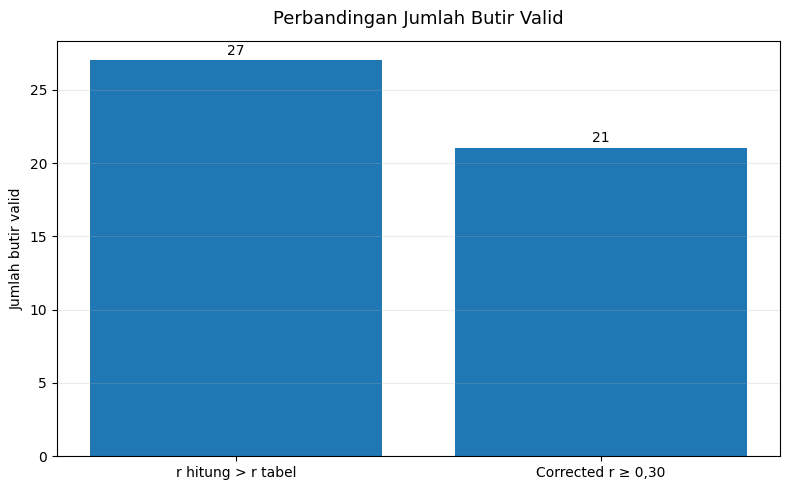

In [ ]:
jumlah_valid_r = int((hasil_semua_validitas["r hitung"] > hasil_semua_validitas["r tabel"]).sum())
jumlah_valid_corrected = int((hasil_semua_validitas["Corrected r"] >= 0.30).sum())
jumlah_butir_total = len(hasil_semua_validitas)

perbandingan_validitas = pd.DataFrame({
    "Kriteria": ["r hitung > r tabel", "Corrected r ≥ 0,30"],
    "Jumlah butir valid": [jumlah_valid_r, jumlah_valid_corrected],
    "Jumlah butir tidak memenuhi": [
        jumlah_butir_total - jumlah_valid_r,
        jumlah_butir_total - jumlah_valid_corrected
    ]
})

display(perbandingan_validitas)
print(f"Selisih jumlah butir valid: {abs(jumlah_valid_r - jumlah_valid_corrected)} butir")

# Visualisasi perbandingan jumlah butir valid
plt.figure(figsize=(8, 5))
bars = plt.bar(perbandingan_validitas["Kriteria"],
               perbandingan_validitas["Jumlah butir valid"])
plt.title("Perbandingan Jumlah Butir Valid", fontsize=13, pad=12)
plt.ylabel("Jumlah butir valid")
plt.grid(axis="y", alpha=0.25)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f"{int(bar.get_height())}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


## Latihan 3 — Perbaikan Instrumen

Satu butir yang tidak valid dihapus dari analisis, kemudian nilai Cronbach's Alpha sebelum dan sesudah penghapusan dibandingkan. Contoh yang digunakan adalah butir tidak valid pertama yang ditemukan pada kelompok **Aspek Psikologis**.

Dimensi: Aspek Psikologis penggunaan AI pada tugas atau projek kuliah
Butir yang dihapus: B7
Pernyataan: Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya tetap merasa yakin terhadap kemampuan diri sendiri pada materi kuliah meskipun menggunakan bantuan AI dalam menyelesaikan tugas kuliah.]


,Keterangan,Jumlah butir,Cronbach's Alpha,Kategori
0,Sebelum butir dihapus,7,0.678,Tidak reliabel
1,Sesudah butir dihapus,6,0.769,Reliabel


Alpha meningkat sebesar 0.091.


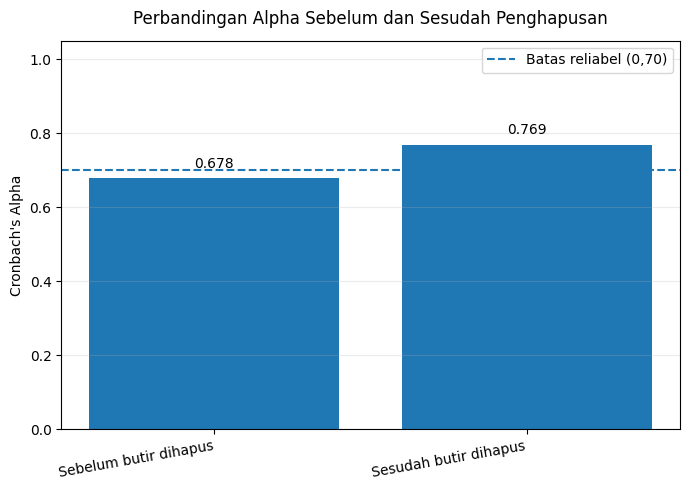

In [ ]:
# Pilih satu butir tidak valid dari kelompok Aspek Psikologis
invalid_psi = val_psi[val_psi["Keterangan"] == "Tidak valid"]

if len(invalid_psi) == 0:
    print("Tidak ditemukan butir tidak valid pada kelompok Aspek Psikologis.")
else:
    baris_pilihan = invalid_psi.iloc[0]
    nama_dimensi_pilihan = baris_pilihan["Dimensi"]
    nomor_butir = int(str(baris_pilihan["Butir"]).replace("B", ""))
    kolom_dihapus = dimensi[nama_dimensi_pilihan][nomor_butir - 1]

    data_sebelum = num[dimensi[nama_dimensi_pilihan]]
    data_sesudah = data_sebelum.drop(columns=[kolom_dihapus])

    alpha_sebelum = cronbach_alpha(data_sebelum)
    alpha_sesudah = cronbach_alpha(data_sesudah)

    perbandingan_alpha = pd.DataFrame({
        "Keterangan": ["Sebelum butir dihapus", "Sesudah butir dihapus"],
        "Jumlah butir": [data_sebelum.shape[1], data_sesudah.shape[1]],
        "Cronbach's Alpha": [round(alpha_sebelum, 3), round(alpha_sesudah, 3)],
        "Kategori": [kategori(alpha_sebelum), kategori(alpha_sesudah)]
    })

    print("Dimensi:", nama_dimensi_pilihan)
    print("Butir yang dihapus:", baris_pilihan["Butir"])
    print("Pernyataan:", kolom_dihapus)
    display(perbandingan_alpha)

    perubahan_alpha = alpha_sesudah - alpha_sebelum
    if perubahan_alpha > 0:
        print(f"Alpha meningkat sebesar {perubahan_alpha:.3f}.")
    elif perubahan_alpha < 0:
        print(f"Alpha menurun sebesar {abs(perubahan_alpha):.3f}.")
    else:
        print("Nilai alpha tidak berubah.")

    # Visualisasi perubahan Cronbach's Alpha
    plt.figure(figsize=(7, 5))
    bars = plt.bar(perbandingan_alpha["Keterangan"],
                   perbandingan_alpha["Cronbach's Alpha"])
    plt.axhline(0.70, linestyle="--", label="Batas reliabel (0,70)")
    plt.ylim(0, 1.05)
    plt.title("Perbandingan Alpha Sebelum dan Sesudah Penghapusan", fontsize=12, pad=12)
    plt.ylabel("Cronbach's Alpha")
    plt.xticks(rotation=10, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    for bar, nilai in zip(bars, perbandingan_alpha["Cronbach's Alpha"]):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f"{nilai:.3f}", ha="center", va="bottom")
    plt.tight_layout()
    plt.show()


## Latihan 4 — Pengaruh Ukuran Sampel

Data diambil secara acak sebanyak 20 responden dari 40 responden. Nilai r tabel dihitung kembali menggunakan jumlah sampel baru, kemudian jumlah butir valid dibandingkan.

Jumlah sampel awal : 40
Jumlah sampel baru : 20
r tabel sampel awal: 0.312
r tabel sampel baru: 0.444


,Dimensi,Butir,r hitung (n=20),r tabel (n=20),Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.369,0.444,Tidak valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.218,0.444,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.520,0.444,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.688,0.444,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.784,0.444,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.638,0.444,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.369,0.444,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B1,0.555,0.444,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B2,0.761,0.444,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau projek ku...,B3,0.765,0.444,Valid


Jumlah valid pada sampel 20: 23
Jumlah tidak dapat dihitung: 0


,Ukuran sampel,Jumlah butir valid
0,n = 40,27
1,n = 20,23


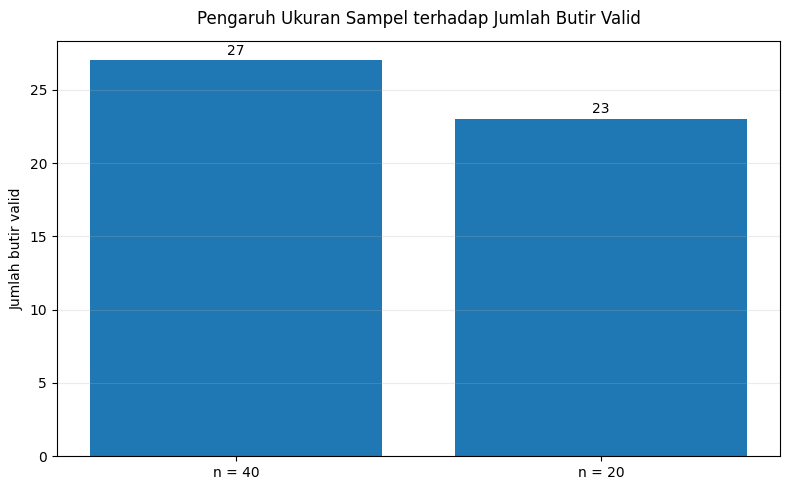

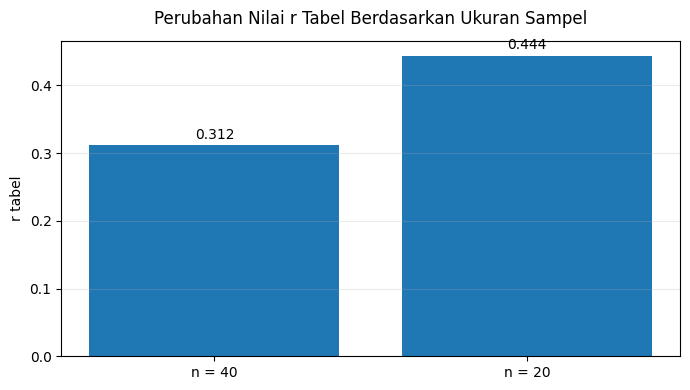

In [ ]:
# Mengambil 20 responden secara acak agar hasil dapat diulang
num_subset = num.sample(n=min(20, len(num)), random_state=1)
n_subset = len(num_subset)
df_subset = n_subset - 2
t_subset = stats.t.ppf(0.975, df_subset)
r_tabel_subset = t_subset / np.sqrt(df_subset + t_subset**2)

print(f"Jumlah sampel awal : {len(num)}")
print(f"Jumlah sampel baru : {n_subset}")
print(f"r tabel sampel awal: {r_tabel:.3f}")
print(f"r tabel sampel baru: {r_tabel_subset:.3f}")

hasil_subset = []
for nama_dimensi, daftar_kolom in dimensi.items():
    x_subset = num_subset[daftar_kolom]
    total_subset = x_subset.sum(axis=1)

    for i, kolom in enumerate(daftar_kolom, 1):
        # Korelasi tidak dapat dihitung jika salah satu variabel tidak memiliki variasi
        if x_subset[kolom].nunique() < 2 or total_subset.nunique() < 2:
            r_subset = np.nan
        else:
            r_subset, _ = stats.pearsonr(x_subset[kolom], total_subset)

        hasil_subset.append({
            "Dimensi": nama_dimensi,
            "Butir": f"B{i}",
            "r hitung (n=20)": round(r_subset, 3) if pd.notna(r_subset) else np.nan,
            "r tabel (n=20)": round(r_tabel_subset, 3),
            "Keterangan": (
                "Valid" if pd.notna(r_subset) and r_subset > r_tabel_subset
                else "Tidak valid" if pd.notna(r_subset)
                else "Tidak dapat dihitung"
            )
        })

tabel_subset = pd.DataFrame(hasil_subset)
display(tabel_subset)

jumlah_valid_subset = int((tabel_subset["Keterangan"] == "Valid").sum())
jumlah_tidak_dapat = int((tabel_subset["Keterangan"] == "Tidak dapat dihitung").sum())
print("Jumlah valid pada sampel 20:", jumlah_valid_subset)
print("Jumlah tidak dapat dihitung:", jumlah_tidak_dapat)

# Visualisasi pengaruh ukuran sampel terhadap jumlah butir valid
jumlah_valid_awal = int((hasil_semua_validitas["Keterangan"] == "Valid").sum())

perbandingan_sampel = pd.DataFrame({
    "Ukuran sampel": [f"n = {len(num)}", f"n = {n_subset}"],
    "Jumlah butir valid": [jumlah_valid_awal, jumlah_valid_subset]
})

display(perbandingan_sampel)

plt.figure(figsize=(8, 5))
bars = plt.bar(perbandingan_sampel["Ukuran sampel"],
               perbandingan_sampel["Jumlah butir valid"])
plt.title("Pengaruh Ukuran Sampel terhadap Jumlah Butir Valid", fontsize=12, pad=12)
plt.ylabel("Jumlah butir valid")
plt.grid(axis="y", alpha=0.25)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             f"{int(bar.get_height())}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Perbandingan nilai r tabel untuk kedua ukuran sampel
plt.figure(figsize=(7, 4))
bars = plt.bar([f"n = {len(num)}", f"n = {n_subset}"],
               [r_tabel, r_tabel_subset])
plt.title("Perubahan Nilai r Tabel Berdasarkan Ukuran Sampel", fontsize=12, pad=12)
plt.ylabel("r tabel")
plt.grid(axis="y", alpha=0.25)
for bar, nilai in zip(bars, [r_tabel, r_tabel_subset]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{nilai:.3f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()
